# Data Science Foundation — Lab Assignment 8: Principal Component Analysis (PCA)

**Datasets:** Iris (`sklearn.datasets.load_iris`) and Breast Cancer Wisconsin (`sklearn.datasets.load_breast_cancer`)  
**Coverage:** All 14 questions for Dataset I and all 16 questions for Dataset II  

This notebook contains executable Python code, observed outputs, plots, tables, and interpretations aligned with the supplied assignment. Run cells top to bottom. PCA is fitted to standardized **features only**; class labels are used for plots, not for PCA fitting. Numerical values may vary slightly by library version and display precision.

**Interpretation note:** PCA component signs are arbitrary: flipping all signs for a component changes neither the variance explained nor its reconstruction quality.

## Setup — libraries and visualization settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 140)
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams['figure.figsize'] = (8, 5)
print('Libraries loaded successfully.')

Libraries loaded successfully.


# Dataset I — Iris

The Iris dataset has **150 records**, **4 numerical features**, and **3 classes**. All steps below correspond to Dataset I tasks A, B, and C.

### Task A — Q1. Load Iris as a DataFrame and show first five rows

In [2]:
iris = load_iris()
X_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
y_iris = pd.Series(iris.target, name='species_code')
iris_names = iris.target_names
print('First five feature records:')
display(X_iris.head())

First five feature records:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1000,3.5000,1.4000,0.2000
1,4.9000,3.0000,1.4000,0.2000
2,4.7000,3.2000,1.3000,0.2000
3,4.6000,3.1000,1.5000,0.2000
4,5.0000,3.6000,1.4000,0.2000


### Task A — Q2. Observations, features, names and target classes

In [3]:
print('Observations:', X_iris.shape[0])
print('Number of features:', X_iris.shape[1])
print('Feature names:', list(X_iris.columns))
print('Target classes:', list(iris_names))
print('Records per class:')
display(y_iris.map(dict(enumerate(iris_names))).value_counts().rename_axis('species').to_frame('count'))

Observations: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Records per class:


,count
species,
setosa,50
versicolor,50
virginica,50


### Task A — Q3. Mean, standard deviation, minimum and maximum; need for standardization

In [4]:
iris_stats = X_iris.agg(['mean', 'std', 'min', 'max']).T
iris_stats.columns = ['Mean', 'Std (sample)', 'Minimum', 'Maximum']
display(iris_stats)

,Mean,Std (sample),Minimum,Maximum
sepal length (cm),5.8433,0.8281,4.3000,7.9000
sepal width (cm),3.0573,0.4359,2.0000,4.4000
petal length (cm),3.7580,1.7653,1.0000,6.9000
petal width (cm),1.1993,0.7622,0.1000,2.5000


**Interpretation:** The features have different means and spreads (for example, petal width and sepal length are on different numerical scales). PCA maximizes variance, so an unscaled variable with larger variance can have disproportionate influence. Standardization centers each feature around zero with unit population standard deviation, making their contributions more comparable.

### Task A — Q4. StandardScaler and first five standardized rows

In [5]:
iris_scaler = StandardScaler()
X_iris_scaled = iris_scaler.fit_transform(X_iris)
X_iris_scaled_df = pd.DataFrame(X_iris_scaled, columns=X_iris.columns)
display(X_iris_scaled_df.head())
print('Standardized column means:', np.round(X_iris_scaled_df.mean().values, 8))
print('Standardized population std:', np.round(X_iris_scaled_df.std(ddof=0).values, 8))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.9007,1.0190,-1.3402,-1.3154
1,-1.1430,-0.1320,-1.3402,-1.3154
2,-1.3854,0.3284,-1.3971,-1.3154
3,-1.5065,0.0982,-1.2834,-1.3154
4,-1.0218,1.2492,-1.3402,-1.3154


Standardized column means: [-0. -0. -0. -0.]
Standardized population std: [1. 1. 1. 1.]


### Task B — Q5. PCA without specifying number of components; explained variance ratios

In [6]:
iris_pca_full = PCA()
iris_pca_full.fit(X_iris_scaled)
iris_ratios = iris_pca_full.explained_variance_ratio_
print('Explained variance ratios (PC1 to PC4):', np.round(iris_ratios, 6))
print('Sum of ratios:', iris_ratios.sum())

Explained variance ratios (PC1 to PC4): [0.729624 0.228508 0.036689 0.005179]
Sum of ratios: 0.9999999999999999


### Task B — Q6. Cumulative explained variance table

In [7]:
iris_variance = pd.DataFrame({'Principal Component': np.arange(1, 5),
                              'Explained Variance Ratio': iris_ratios,
                              'Cumulative Variance Ratio': iris_ratios.cumsum(),
                              'Cumulative Variance (%)': iris_ratios.cumsum()*100})
display(iris_variance)

,Principal Component,Explained Variance Ratio,Cumulative Variance Ratio,Cumulative Variance (%)
0,1,0.7296,0.7296,72.9624
1,2,0.2285,0.9581,95.8132
2,3,0.0367,0.9948,99.4821
3,4,0.0052,1.0000,100.0000


### Task B — Q7. Explained variance ratio versus principal component number

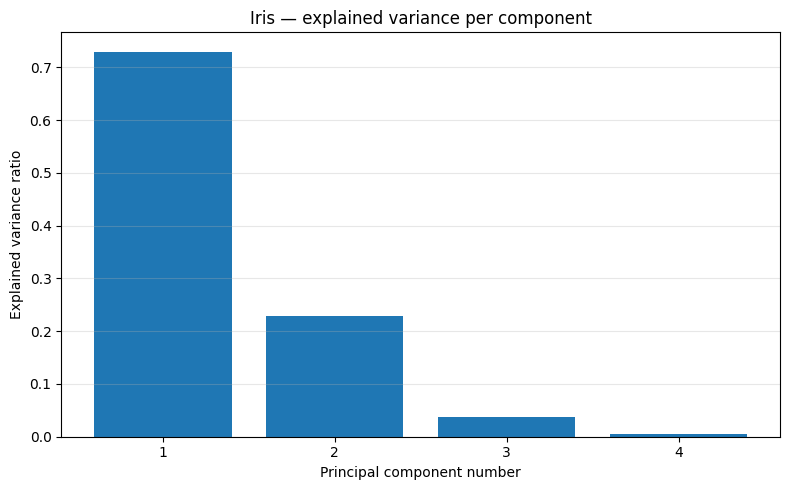

In [8]:
plt.figure()
plt.bar(iris_variance['Principal Component'], iris_ratios)
plt.xticks([1,2,3,4]); plt.xlabel('Principal component number'); plt.ylabel('Explained variance ratio')
plt.title('Iris — explained variance per component'); plt.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

### Task B — Q8. Cumulative explained variance and minimum components for ≥90%

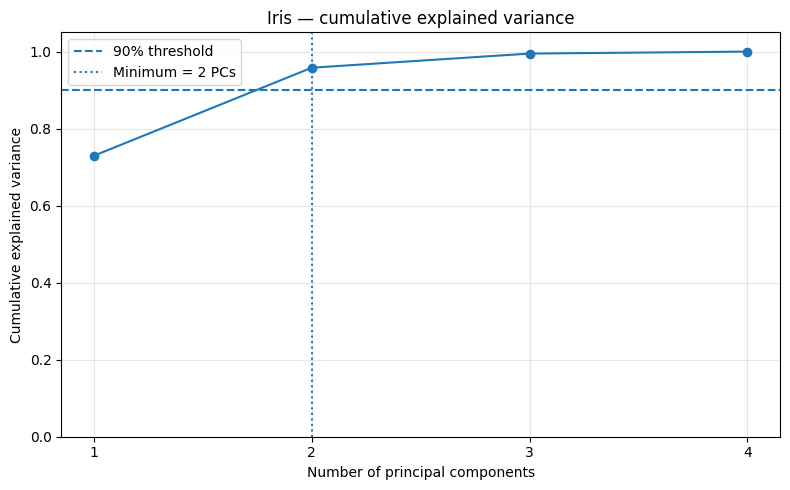

Minimum PCs retaining >=90%: 2; retained variance = 95.81%


In [9]:
iris_k90 = int(np.searchsorted(iris_ratios.cumsum(), .90) + 1)
plt.figure()
plt.plot(np.arange(1,5), iris_ratios.cumsum(), marker='o')
plt.axhline(.90, linestyle='--', label='90% threshold')
plt.axvline(iris_k90, linestyle=':', label=f'Minimum = {iris_k90} PCs')
plt.xticks([1,2,3,4]); plt.ylim(0, 1.05)
plt.xlabel('Number of principal components'); plt.ylabel('Cumulative explained variance')
plt.title('Iris — cumulative explained variance'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f'Minimum PCs retaining >=90%: {iris_k90}; retained variance = {iris_ratios[:iris_k90].sum():.2%}')

### Task B — Q9. PCA with two components; transformed values and shape

In [10]:
iris_pca_2 = PCA(n_components=2)
Z_iris_2 = iris_pca_2.fit_transform(X_iris_scaled)
Z_iris_df = pd.DataFrame(Z_iris_2, columns=['PC1', 'PC2'])
display(Z_iris_df.head())
print('Original dimensions:', X_iris.shape, 'Reduced dimensions:', Z_iris_df.shape)

,PC1,PC2
0,-2.2647,0.4800
1,-2.0810,-0.6741
2,-2.3642,-0.3419
3,-2.2994,-0.5974
4,-2.3898,0.6468


Original dimensions: (150, 4) Reduced dimensions: (150, 2)


### Task B — Q10. Principal component vectors and strongest original features

In [11]:
iris_vectors = pd.DataFrame(iris_pca_2.components_.T, index=X_iris.columns, columns=['PC1','PC2'])
print('PCA component coefficients (rows: original features):')
display(iris_vectors)
for pc in iris_vectors.columns:
    ranking = iris_vectors[pc].abs().sort_values(ascending=False)
    print(f'{pc} strongest contributors by absolute coefficient:', ', '.join(f'{f} ({iris_vectors.loc[f,pc]:+.3f})' for f in ranking.index[:2]))

PCA component coefficients (rows: original features):


,PC1,PC2
sepal length (cm),0.5211,0.3774
sepal width (cm),-0.2693,0.9233
petal length (cm),0.5804,0.0245
petal width (cm),0.5649,0.0669


PC1 strongest contributors by absolute coefficient: petal length (cm) (+0.580), petal width (cm) (+0.565)
PC2 strongest contributors by absolute coefficient: sepal width (cm) (+0.923), sepal length (cm) (+0.377)


**Interpretation:** Larger *absolute component coefficients* indicate stronger contributions to the component for standardized features. The sign shows direction, not importance. The `components_` vectors are often called loadings in introductory exercises; statistically scaled loadings can alternatively be defined using the eigenvalues.

### Task C — Q11. PCA scatter plot colored by Iris species

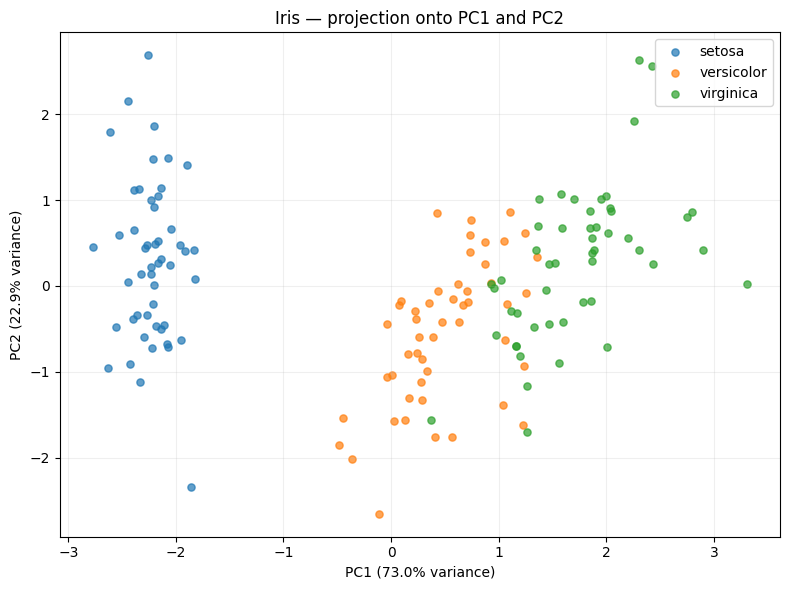

In [12]:
plt.figure(figsize=(8,6))
for i, name in enumerate(iris_names):
    mask = y_iris.to_numpy() == i
    plt.scatter(Z_iris_2[mask,0], Z_iris_2[mask,1], label=name, alpha=.7, s=27)
plt.xlabel(f'PC1 ({iris_pca_2.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({iris_pca_2.explained_variance_ratio_[1]:.1%} variance)')
plt.title('Iris — projection onto PC1 and PC2'); plt.legend(); plt.grid(alpha=.2)
plt.tight_layout(); plt.show()

### Task C — Q12. Compare original feature space with reduced 2D PCA space

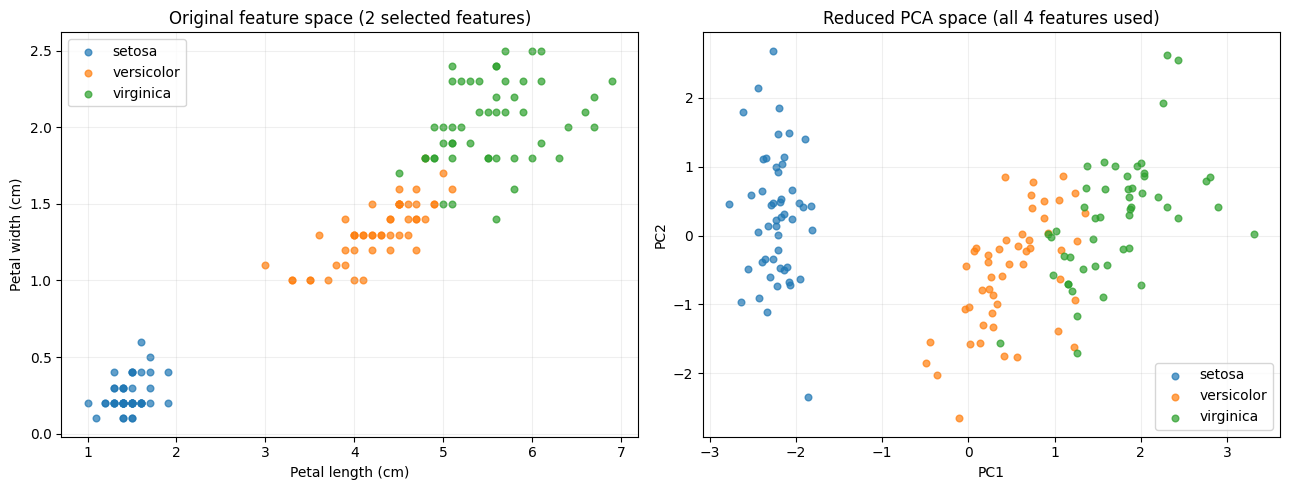

In [13]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
for i,name in enumerate(iris_names):
    m = y_iris.to_numpy() == i
    axes[0].scatter(X_iris.iloc[m,2], X_iris.iloc[m,3], label=name, alpha=.7, s=23)
    axes[1].scatter(Z_iris_2[m,0], Z_iris_2[m,1], label=name, alpha=.7, s=23)
axes[0].set(xlabel='Petal length (cm)',ylabel='Petal width (cm)',title='Original feature space (2 selected features)')
axes[1].set(xlabel='PC1',ylabel='PC2',title='Reduced PCA space (all 4 features used)')
for ax in axes: ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation:** Iris-setosa tends to form a distinct cluster in both the petal-feature view and the PCA projection. Versicolor and virginica show partial overlap. The original-space plot above uses **two selected original features** because a four-dimensional space cannot be shown directly in a 2D scatter plot; PCA, by contrast, combines information from all four standardized features into two axes.

### Task C — Q13. Percentage of total variance retained using two components

In [14]:
iris_pct2 = iris_pca_2.explained_variance_ratio_.sum() * 100
print(f'Iris variance retained by PC1+PC2: {iris_pct2:.4f}%')
print(f'Iris variance discarded: {100-iris_pct2:.4f}%')

Iris variance retained by PC1+PC2: 95.8132%
Iris variance discarded: 4.1868%


### Task C — Q14. Approximate reconstruction of the standardized data

In [15]:
X_iris_reconstructed = iris_pca_2.inverse_transform(Z_iris_2)
iris_reconstructed_df = pd.DataFrame(X_iris_reconstructed, columns=X_iris.columns)
print('First five reconstructed standardized rows:')
display(iris_reconstructed_df.head())
print('First five original standardized rows:')
display(X_iris_scaled_df.head())
print(f'Reconstruction MSE (standardized units): {mean_squared_error(X_iris_scaled, X_iris_reconstructed):.6f}')

First five reconstructed standardized rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.9989,1.0532,-1.3027,-1.2471
1,-1.3387,-0.0619,-1.2243,-1.2206
2,-1.3610,0.3211,-1.3806,-1.3583
3,-1.4236,0.0678,-1.3492,-1.3388
4,-1.0011,1.2409,-1.3713,-1.3066


First five original standardized rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.9007,1.0190,-1.3402,-1.3154
1,-1.1430,-0.1320,-1.3402,-1.3154
2,-1.3854,0.3284,-1.3971,-1.3154
3,-1.5065,0.0982,-1.2834,-1.3154
4,-1.0218,1.2492,-1.3402,-1.3154


Reconstruction MSE (standardized units): 0.041868


**Interpretation:** The reconstruction is approximate because two components discard some of the original feature-space variance. `inverse_transform` reconstructs standardized features; to recover their approximate values in original centimeters, additionally call `iris_scaler.inverse_transform(X_iris_reconstructed)`.

---
# Dataset II — Breast Cancer Wisconsin

This dataset has **569 observations**, **30 numerical features**, and two classes: **malignant** and **benign**. We repeat the PCA workflow with the more detailed diagnostics required by its 16 questions.

### Task A — Q1. Load Breast Cancer Wisconsin dataset and show first five records

In [16]:
cancer = load_breast_cancer()
X_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_cancer = pd.Series(cancer.target, name='diagnosis_code')
cancer_names = cancer.target_names
print('First five feature rows:')
display(X_cancer.head())

First five feature rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


### Task A — Q2. Observations, feature count, names and classes

In [17]:
print('Observations:', X_cancer.shape[0]); print('Features:', X_cancer.shape[1])
print('Feature names:', list(X_cancer.columns)); print('Target classes:', list(cancer_names))
display(y_cancer.map(dict(enumerate(cancer_names))).value_counts().rename_axis('diagnosis').to_frame('count'))

Observations: 569
Features: 30
Feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target classes: [np.str_('malignant'), np.str_('benign')]


,count
diagnosis,
benign,357
malignant,212


### Task A — Q3. Feature summary statistics and different value ranges

In [18]:
cancer_stats = X_cancer.agg(['mean','std','min','max']).T
cancer_stats.columns = ['Mean','Std (sample)','Minimum','Maximum']
cancer_stats['Range'] = cancer_stats['Maximum'] - cancer_stats['Minimum']
display(cancer_stats)
print('Five features with largest observed ranges:')
display(cancer_stats.sort_values('Range', ascending=False).head()[['Minimum','Maximum','Range']])
print('Five features with smallest observed ranges:')
display(cancer_stats.sort_values('Range', ascending=True).head()[['Minimum','Maximum','Range']])

,Mean,Std (sample),Minimum,Maximum,Range
mean radius,14.1273,3.5240,6.9810,28.1100,21.1290
mean texture,19.2896,4.3010,9.7100,39.2800,29.5700
mean perimeter,91.9690,24.2990,43.7900,188.5000,144.7100
mean area,654.8891,351.9141,143.5000,2501.0000,2357.5000
mean smoothness,0.0964,0.0141,0.0526,0.1634,0.1108
mean compactness,0.1043,0.0528,0.0194,0.3454,0.3260
mean concavity,0.0888,0.0797,0.0000,0.4268,0.4268
mean concave points,0.0489,0.0388,0.0000,0.2012,0.2012
mean symmetry,0.1812,0.0274,0.1060,0.3040,0.1980
mean fractal dimension,0.0628,0.0071,0.0500,0.0974,0.0475


Five features with largest observed ranges:


,Minimum,Maximum,Range
worst area,185.2000,4254.0000,4068.8000
mean area,143.5000,2501.0000,2357.5000
area error,6.8020,542.2000,535.3980
worst perimeter,50.4100,251.2000,200.7900
mean perimeter,43.7900,188.5000,144.7100


Five features with smallest observed ranges:


,Minimum,Maximum,Range
fractal dimension error,0.0009,0.0298,0.0289
smoothness error,0.0017,0.0311,0.0294
mean fractal dimension,0.0500,0.0974,0.0475
concave points error,0.0000,0.0528,0.0528
symmetry error,0.0079,0.0790,0.0711


**Interpretation:** Features such as *worst area* and *mean area* have much larger raw numerical ranges than features such as *smoothness error* or *fractal dimension error*. Without scaling, raw variance can dominate principal components. These features must be standardized before the PCA comparison in this lab.

### Task A — Q4. Missing values and duplicate records

In [19]:
missing_by_col = X_cancer.isna().sum()
print('Total missing cells:', int(missing_by_col.sum()))
print('Columns with missing data:')
display(missing_by_col[missing_by_col>0].to_frame('Missing count'))
print('Exact duplicate feature rows:', int(X_cancer.duplicated().sum()))
print('Exact duplicate full rows including class:', int(pd.concat([X_cancer,y_cancer],axis=1).duplicated().sum()))

Total missing cells: 0
Columns with missing data:


,Missing count


Exact duplicate feature rows: 0
Exact duplicate full rows including class: 0


### Task A — Q5. Standardize 30 features and show first five rows

In [20]:
cancer_scaler = StandardScaler()
X_cancer_scaled = cancer_scaler.fit_transform(X_cancer)
X_cancer_scaled_df = pd.DataFrame(X_cancer_scaled,columns=X_cancer.columns)
display(X_cancer_scaled_df.head())
print('Maximum absolute standardized mean:', abs(X_cancer_scaled.mean(axis=0)).max())
print('Standardized population standard deviations (min/max):', X_cancer_scaled.std(axis=0).min(), X_cancer_scaled.std(axis=0).max())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1.0971,-2.0733,1.2699,0.9844,1.5685,3.2835,2.6529,2.5325,2.2175,2.2557,2.4897,-0.5653,2.8330,2.4876,-0.2140,1.3169,0.7240,0.6608,1.1488,0.9071,1.8867,-1.3593,2.3036,2.0012,1.3077,2.6167,2.1095,2.2961,2.7506,1.9370
1,1.8298,-0.3536,1.6860,1.9087,-0.8270,-0.4871,-0.0238,0.5481,0.0014,-0.8687,0.4993,-0.8762,0.2633,0.7424,-0.6054,-0.6929,-0.4408,0.2602,-0.8055,-0.0994,1.8059,-0.3692,1.5351,1.8905,-0.3756,-0.4304,-0.1467,1.0871,-0.2439,0.2812
2,1.5799,0.4562,1.5665,1.5589,0.9422,1.0529,1.3635,2.0372,0.9397,-0.3980,1.2287,-0.7801,0.8509,1.1813,-0.2970,0.8150,0.2131,1.4248,0.2370,0.2936,1.5119,-0.0240,1.3475,1.4563,0.5274,1.0829,0.8550,1.9550,1.1523,0.2014
3,-0.7689,0.2537,-0.5927,-0.7645,3.2836,3.4029,1.9159,1.4517,2.8674,4.9109,0.3264,-0.1104,0.2866,-0.2884,0.6897,2.7443,0.8195,1.1150,4.7327,2.0475,-0.2815,0.1340,-0.2499,-0.5500,3.3943,3.8934,1.9896,2.1758,6.0460,4.9350
4,1.7503,-1.1518,1.7766,1.8262,0.2804,0.5393,1.3710,1.4285,-0.0096,-0.5624,1.2705,-0.7902,1.2732,1.1904,1.4831,-0.0485,0.8285,1.1442,-0.3611,0.4993,1.2986,-1.4668,1.3385,1.2207,0.2206,-0.3134,0.6132,0.7293,-0.8684,-0.3971


Maximum absolute standardized mean: 6.530608898805622e-15
Standardized population standard deviations (min/max): 0.999999999999999 1.0000000000000013


### Task B — Q6. Full PCA (30 components) and explained variance ratios

In [21]:
cancer_pca_full = PCA()
cancer_pca_full.fit(X_cancer_scaled)
cancer_ratios = cancer_pca_full.explained_variance_ratio_
print('All 30 explained variance ratios:')
display(pd.DataFrame({'PC':np.arange(1,31),'Explained variance ratio':cancer_ratios}))

All 30 explained variance ratios:


,PC,Explained variance ratio
0,1,0.4427
1,2,0.1897
2,3,0.0939
3,4,0.0660
4,5,0.0550
5,6,0.0402
6,7,0.0225
7,8,0.0159
8,9,0.0139
9,10,0.0117


### Task B — Q7. Cumulative explained variance of all components

In [22]:
cancer_variance = pd.DataFrame({'PC':np.arange(1,31),
                               'Explained variance ratio':cancer_ratios,
                               'Cumulative variance ratio':np.cumsum(cancer_ratios),
                               'Cumulative variance (%)':100*np.cumsum(cancer_ratios)})
display(cancer_variance)

,PC,Explained variance ratio,Cumulative variance ratio,Cumulative variance (%)
0,1,0.4427,0.4427,44.2720
1,2,0.1897,0.6324,63.2432
2,3,0.0939,0.7264,72.6364
3,4,0.0660,0.7924,79.2385
4,5,0.0550,0.8473,84.7343
5,6,0.0402,0.8876,88.7588
6,7,0.0225,0.9101,91.0095
7,8,0.0159,0.9260,92.5983
8,9,0.0139,0.9399,93.9879
9,10,0.0117,0.9516,95.1569


### Task B — Q8. Explained variance ratio graph

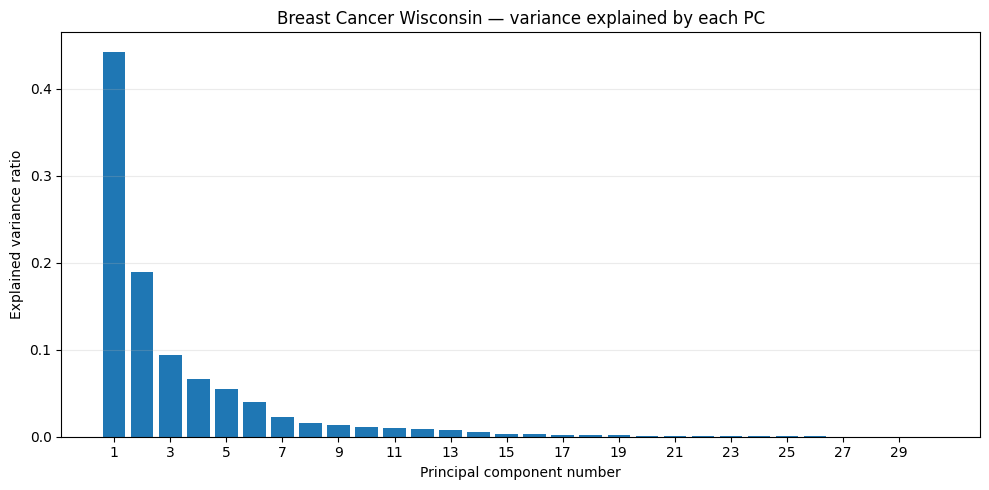

In [23]:
plt.figure(figsize=(10,5))
plt.bar(np.arange(1,31),cancer_ratios)
plt.xlabel('Principal component number');plt.ylabel('Explained variance ratio')
plt.xticks(np.arange(1,31,2)); plt.title('Breast Cancer Wisconsin — variance explained by each PC')
plt.grid(axis='y',alpha=.25); plt.tight_layout(); plt.show()

### Task B — Q9. Cumulative graph and minimum components for ≥90% variance

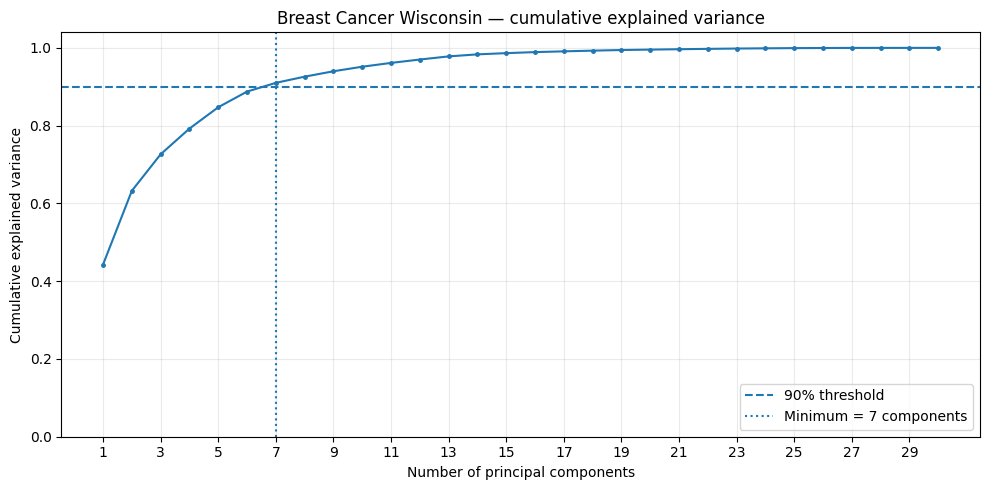

Minimum number of PCs to retain >=90%: 7
Variance retained by first 7 PCs: 91.0095%


In [24]:
cancer_k90 = int(np.searchsorted(np.cumsum(cancer_ratios), .90) + 1)
plt.figure(figsize=(10,5))
plt.plot(np.arange(1,31),np.cumsum(cancer_ratios),marker='.',markersize=5)
plt.axhline(.9,linestyle='--',label='90% threshold')
plt.axvline(cancer_k90,linestyle=':',label=f'Minimum = {cancer_k90} components')
plt.xlabel('Number of principal components');plt.ylabel('Cumulative explained variance')
plt.xticks(np.arange(1,31,2));plt.ylim(0,1.04);plt.grid(alpha=.25);plt.legend()
plt.title('Breast Cancer Wisconsin — cumulative explained variance');plt.tight_layout();plt.show()
print(f'Minimum number of PCs to retain >=90%: {cancer_k90}')
print(f'Variance retained by first {cancer_k90} PCs: {cancer_ratios[:cancer_k90].sum():.4%}')

### Task B — Q10. PCA keeping only PC1 and PC2

In [25]:
cancer_pca_2 = PCA(n_components=2)
Z_cancer_2 = cancer_pca_2.fit_transform(X_cancer_scaled)
Z_cancer_df = pd.DataFrame(Z_cancer_2,columns=['PC1','PC2'])
display(Z_cancer_df.head())
print('Original shape:',X_cancer.shape,'PCA 2D shape:',Z_cancer_df.shape)

,PC1,PC2
0,9.1928,1.9486
1,2.3878,-3.7682
2,5.7339,-1.0752
3,7.1230,10.2756
4,3.9353,-1.9481


Original shape: (569, 30) PCA 2D shape: (569, 2)


### Task B — Q11. Component vectors and most influential original features

In [26]:
cancer_vectors = pd.DataFrame(cancer_pca_2.components_.T, index=X_cancer.columns,columns=['PC1','PC2'])
display(cancer_vectors)
for pc in cancer_vectors.columns:
    ranks = cancer_vectors[pc].abs().sort_values(ascending=False)
    print(f'Top 5 original features contributing to {pc} (ranked by absolute coefficient):')
    display(pd.DataFrame({'coefficient':cancer_vectors.loc[ranks.index[:5],pc],
                          'absolute coefficient':ranks.iloc[:5]}))

,PC1,PC2
mean radius,0.2189,-0.2339
mean texture,0.1037,-0.0597
mean perimeter,0.2275,-0.2152
mean area,0.2210,-0.2311
mean smoothness,0.1426,0.1861
mean compactness,0.2393,0.1519
mean concavity,0.2584,0.0602
mean concave points,0.2609,-0.0348
mean symmetry,0.1382,0.1903
mean fractal dimension,0.0644,0.3666


Top 5 original features contributing to PC1 (ranked by absolute coefficient):


,coefficient,absolute coefficient
mean concave points,0.2609,0.2609
mean concavity,0.2584,0.2584
worst concave points,0.2509,0.2509
mean compactness,0.2393,0.2393
worst perimeter,0.2366,0.2366


Top 5 original features contributing to PC2 (ranked by absolute coefficient):


,coefficient,absolute coefficient
mean fractal dimension,0.3666,0.3666
fractal dimension error,0.2801,0.2801
worst fractal dimension,0.2753,0.2753
mean radius,-0.2339,0.2339
compactness error,0.2327,0.2327


### Task C — Q12. PC1/PC2 scatter plot colored by diagnosis

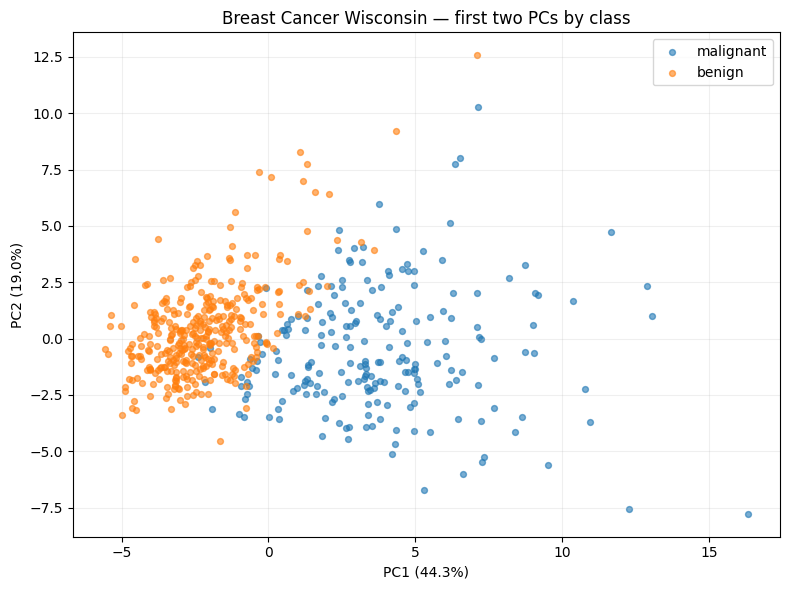

In [27]:
plt.figure(figsize=(8,6))
for i, name in enumerate(cancer_names):
    mask = y_cancer.to_numpy()==i
    plt.scatter(Z_cancer_2[mask,0],Z_cancer_2[mask,1],s=18,alpha=.6,label=name)
plt.xlabel(f'PC1 ({cancer_pca_2.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PC2 ({cancer_pca_2.explained_variance_ratio_[1]:.1%})')
plt.title('Breast Cancer Wisconsin — first two PCs by class')
plt.legend();plt.grid(alpha=.2);plt.tight_layout();plt.show()

### Task C — Q13. Do the malignant and benign classes separate or overlap?

**Interpretation:** The two classes show substantial separation along PC1, but there is some overlap between their point clouds in the two-dimensional plot. Thus PCA gives a useful visual summary, but the first two PCs do **not** guarantee perfect classification. PCA is unsupervised: it maximizes overall variance, not class separation.

### Task C — Q14. Percentage of variance retained in two dimensions

In [28]:
cancer_pct2 = 100*cancer_pca_2.explained_variance_ratio_.sum()
print(f'Variance retained using 2 PCs: {cancer_pct2:.4f}%')
print(f'Variance not retained in 2D: {100-cancer_pct2:.4f}%')

Variance retained using 2 PCs: 63.2432%
Variance not retained in 2D: 36.7568%


### Task C — Q15. Reconstruct standardized data from two PCs; compute error

In [29]:
X_cancer_recon2 = cancer_pca_2.inverse_transform(Z_cancer_2)
cancer_mse2 = mean_squared_error(X_cancer_scaled, X_cancer_recon2)
print('Original standardized shape:',X_cancer_scaled.shape)
print('Reconstructed standardized shape:',X_cancer_recon2.shape)
print('First five reconstructed rows (all 30 features):')
display(pd.DataFrame(X_cancer_recon2,columns=X_cancer.columns).head())
print(f'Reconstruction mean squared error (2 PCs): {cancer_mse2:.8f}')
print(f'Reconstruction root mean squared error (2 PCs): {np.sqrt(cancer_mse2):.8f}')

Original standardized shape: (569, 30)
Reconstructed standardized shape: (569, 30)
First five reconstructed rows (all 30 features):


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1.5566,0.8372,1.6724,1.5813,1.6735,2.4957,2.4927,2.3302,1.6411,1.3060,1.6879,0.3355,1.7684,1.5682,0.5319,2.0199,1.7962,1.9401,0.7489,1.4887,1.6675,0.8718,1.7859,1.6398,1.5120,2.2112,2.2939,2.2903,1.4063,1.7480
1,1.4039,0.4727,1.3542,1.3984,-0.3608,-0.0010,0.3903,0.7539,-0.3874,-1.2276,0.8896,-0.2974,0.8417,1.0583,-0.7356,-0.4700,-0.3764,-0.0531,-0.5913,-0.8105,1.3729,0.4208,1.3182,1.3635,-0.3437,-0.0394,0.1771,0.6302,-0.2412,-0.7229
2,1.5066,0.6589,1.5360,1.5156,0.6175,1.2087,1.4170,1.5331,0.5876,-0.0251,1.2945,0.0032,1.3079,1.3270,-0.1365,0.7268,0.6686,0.9116,0.0460,0.2870,1.5437,0.6479,1.5718,1.5252,0.5484,1.0503,1.2064,1.4474,0.5522,0.4596
3,-0.8438,0.1253,-0.5904,-0.8003,2.9281,3.2652,2.4588,1.5008,2.9401,4.2252,0.3826,1.0487,0.5860,-0.1199,2.2042,3.6050,3.1204,2.6456,2.1919,3.6087,-0.6352,0.2769,-0.3683,-0.6522,2.6819,2.9720,2.6361,1.7022,2.3334,3.7680
4,1.3170,0.5245,1.3146,1.3198,0.1986,0.6458,0.8997,1.0943,0.1729,-0.4608,1.0162,-0.1067,1.0059,1.0950,-0.3411,0.2172,0.2202,0.4679,-0.1909,-0.1420,1.3256,0.4997,1.3206,1.3122,0.1679,0.5471,0.7094,1.0034,0.2073,-0.0178


Reconstruction mean squared error (2 PCs): 0.36756792
Reconstruction root mean squared error (2 PCs): 0.60627380


**Error definition:** `MSE = mean((standardized_original - standardized_reconstruction)²)`, averaged across every row and feature. This is an *in-sample reconstruction error in standardized feature units*, not a diagnostic prediction error.

### Task C — Q16. Reconstruct using ≥90% components; compare errors

In [30]:
cancer_pca_90 = PCA(n_components=cancer_k90)
Z_cancer_90 = cancer_pca_90.fit_transform(X_cancer_scaled)
X_cancer_recon90 = cancer_pca_90.inverse_transform(Z_cancer_90)
cancer_mse90 = mean_squared_error(X_cancer_scaled,X_cancer_recon90)
comparison = pd.DataFrame({'Number of components':[2,cancer_k90],
                           'Variance retained (%)':[cancer_pct2,100*cancer_pca_90.explained_variance_ratio_.sum()],
                           'Reconstruction MSE':[cancer_mse2,cancer_mse90],
                           'Reconstruction RMSE':[np.sqrt(cancer_mse2),np.sqrt(cancer_mse90)]},
                          index=['First two PCs','At least 90% variance'])
display(comparison)
print(f'MSE reduction using {cancer_k90} rather than 2 PCs: {cancer_mse2-cancer_mse90:.8f}')
print('Lower reconstruction error for 90% PCA:', cancer_mse90 < cancer_mse2)

,Number of components,Variance retained (%),Reconstruction MSE,Reconstruction RMSE
First two PCs,2,63.2432,0.3676,0.6063
At least 90% variance,7,91.0095,0.0899,0.2998


MSE reduction using 7 rather than 2 PCs: 0.27766322
Lower reconstruction error for 90% PCA: True


**Interpretation:** Keeping enough components to retain at least 90% of total variance reduces the information lost in reconstruction and therefore decreases the mean squared reconstruction error compared with only two PCs. The trade-off is a higher-dimensional reduced representation.

---
## Final conclusions

- Standardization makes PCA results less dominated by numerical feature scales.
- Iris can be represented effectively in two principal components; the scatter plot largely separates setosa while the other two species partly overlap.
- Breast Cancer Wisconsin is higher-dimensional; reducing it to two PCs helps visualization but discards more information than a ≥90%-variance representation.
- Reconstruction error decreases as more components are retained (for these fits).
- Class labels are used solely for interpretation and plots; they were **not** used to fit PCA.

## References
1. Scikit-learn documentation: `load_iris`, `load_breast_cancer`, `StandardScaler`, and `sklearn.decomposition.PCA` — https://scikit-learn.org/stable/
2. Pandas documentation — https://pandas.pydata.org/docs/
3. Matplotlib documentation — https://matplotlib.org/stable/
4. Provided course handout, **Lab Assignment: Principal Component Analysis (PCA)**, Dataset I and Dataset II.